# In-class Competition: Home Credit Default Risk — solución final
**Autor:** Mateo Pozo · GCI World 2026

- Métrica: ROC-AUC. Validación: StratifiedKFold de 5 folds (semilla 42).
- Variables: limpieza de valores centinela, ratios de crédito/ingreso/anualidad, combinaciones de EXT_SOURCE, estimación de EXT_SOURCE_1/2/3 a partir de las demás columnas (sin usar TARGET) y estructura del préstamo (plazo y tasa de interés implícita).
- Modelo: mezcla de LightGBM (5 semillas, hiperparámetros ajustados con Optuna), XGBoost y CatBoost (depth 5), pesos 0.50 / 0.25 / 0.25.
- AUC de validación (out-of-fold) obtenido: **0.7685**.
- Solo se usan `input/train.csv` y `input/test.csv`; sin datos externos ni etiquetado manual.

Ejecutar todas las celdas en orden (Runtime → Restart and run all). Tiempo aproximado: ~1 h con 8 núcleos (más en Colab).


## 1. Setup
### 1.1 Librerías y semillas

In [ ]:
%pip install -q lightgbm xgboost catboost

In [2]:
import os, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost, catboost, sklearn
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.metrics import roc_auc_score
from scipy.signal import find_peaks
warnings.filterwarnings('ignore')

SEED = 42
N_JOBS = 8   # hilos para LightGBM / XGBoost / CatBoost
random.seed(SEED)
np.random.seed(SEED)
print('pandas', pd.__version__, '| lightgbm', lgb.__version__, '| xgboost', xgboost.__version__,
      '| catboost', catboost.__version__, '| sklearn', sklearn.__version__)

pandas 3.1.1 | lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10 | sklearn 1.9.1


### 1.2 Ruta de la carpeta Competition
En Colab se monta Drive y se usa `COLAB_DIR` (cámbialo si tu carpeta está en otra ruta). En local, abre el notebook dentro de la carpeta `Competition`.

In [3]:
COLAB_DIR = '/content/drive/MyDrive/Competition'
try:
    from google.colab import drive
    drive.mount('/content/drive')
    current_dir = Path(COLAB_DIR)
except ImportError:
    current_dir = Path(os.getcwd())

train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.", current_dir)

All files exist and path is correctly set.


## 2. Carga de datos

In [4]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)
assert (sample_sub["SK_ID_CURR"].values == test["SK_ID_CURR"].values).all()
y = train["TARGET"].values
print('train', train.shape, '| test', test.shape, '| tasa TARGET=1:', round(y.mean(), 4))

train (171202, 34) | test (61500, 33) | tasa TARGET=1: 0.0807


## 3. Hallazgos del análisis exploratorio
- `TARGET` desbalanceado (~8% de incumplimientos) → se usa ROC-AUC y validación estratificada.
- `DAYS_EMPLOYED = 365243` es un valor centinela (30.898 filas), las mismas filas con `ORGANIZATION_TYPE = "XNA"` → se convierten a nulo y se agrega una bandera.
- `XNA` en `CODE_GENDER` y `Unknown` en `NAME_FAMILY_STATUS` son nulos disfrazados.
- `EXT_SOURCE_1/2/3` son las variables más predictivas; `EXT_SOURCE_1` tiene ~70% de nulos.
- Montos con colas largas → los ratios entre crédito, anualidad, ingreso y precio del bien son más informativos que los montos solos.

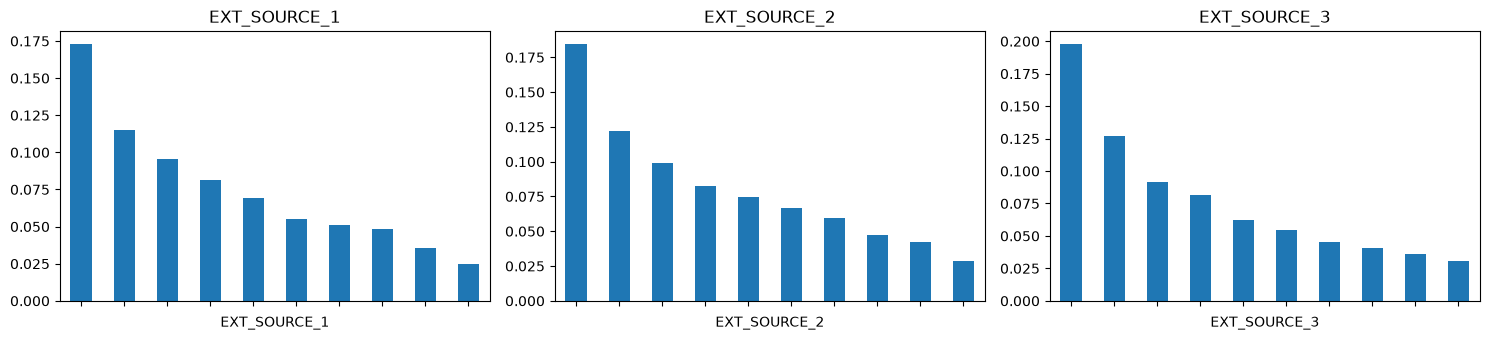

EXT_SOURCE_1                  0.694665
OWN_CAR_AGE                   0.659992
EXT_SOURCE_3                  0.318840
AMT_REQ_CREDIT_BUREAU_MON     0.135022
AMT_REQ_CREDIT_BUREAU_QRT     0.135022
AMT_REQ_CREDIT_BUREAU_HOUR    0.135022
AMT_REQ_CREDIT_BUREAU_YEAR    0.135022
EXT_SOURCE_2                  0.002155
dtype: float64

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for i, c in enumerate(["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    train.groupby(pd.qcut(train[c], 10), observed=True)["TARGET"].mean().plot(kind="bar", ax=ax[i], title=c)
    ax[i].set_xticklabels([])
plt.tight_layout(); plt.show()
train.isnull().mean().sort_values(ascending=False).head(8)

## 4. Preprocesamiento y creación de variables
Se procesan train y test juntos (sin la columna TARGET) para que las categorías sean consistentes. Los árboles manejan nulos y categorías de forma nativa, así que no se escala.

**Estimación de EXT_SOURCE.** `EXT_SOURCE_1` (~70% nulos) y `EXT_SOURCE_3` (~32%) son las variables más predictivas pero tienen muchos nulos. Para cada una se entrena un modelo de regresión (LightGBM) que la estima a partir de las demás columnas originales, **sin usar TARGET**. En las filas donde el valor existe se usa una predicción fuera de fold (5 folds) para no copiar el valor real; en las filas con nulo se usa el promedio de los 5 modelos. Se añaden la estimación (`_PRED`), la columna rellenada (`_FILL`) y su media/producto. Mejora la validación en las 3 semillas probadas (+0.0009 de media).

**Estructura del préstamo.** `AMT_CREDIT / AMT_ANNUITY` aproxima el número de cuotas, pero sale algo menor que el plazo real porque la anualidad incluye intereses. Su distribución (train+test, sin TARGET) tiene picos claros: cada pico corresponde a una combinación de plazo y tasa. Se agregan el pico más cercano, la distancia (absoluta y relativa) al pico y la posición entre picos vecinos. Además, tomando como plazo el estándar más pequeño (6, 10, 12, 18, 24, 30, 36… meses) que sea mayor o igual al cociente, se resuelve la **tasa de interés implícita** de la fórmula de anualidad y el interés total relativo. Mejora la validación en los 5 folds en dos particiones distintas (semillas 42 y 2027): de 0.7631 a 0.7665 y de 0.7622 a 0.7660 (LightGBM rápido).

Experimentos descartados por no mejorar la validación: estadísticas por grupo (ingreso relativo por ocupación, etc.), target encoding dentro de cada fold, media de TARGET de los 500 vecinos más cercanos, diferencias entre fechas, conteo de solicitudes con perfil repetido y residuos de la estimación de EXT_SOURCE.


In [6]:
def base_fe(df):
    df = df.copy()
    df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
    df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)
    for c in ["ORGANIZATION_TYPE","CODE_GENDER"]:
        df[c] = df[c].replace("XNA", np.nan)
    df["NAME_FAMILY_STATUS"] = df["NAME_FAMILY_STATUS"].replace("Unknown", np.nan)
    ext = ["EXT_SOURCE_1","EXT_SOURCE_2","EXT_SOURCE_3"]; e = df[ext]
    df["EXT_MEAN"]=e.mean(axis=1); df["EXT_MIN"]=e.min(axis=1); df["EXT_MAX"]=e.max(axis=1)
    df["EXT_STD"]=e.std(axis=1); df["EXT_PROD"]=e.prod(axis=1, min_count=3)
    df["EXT_NA"]=e.isna().sum(axis=1)
    df["EXT_W"]=df.EXT_SOURCE_1*2+df.EXT_SOURCE_2*1+df.EXT_SOURCE_3*3
    df["CREDIT_INCOME"]=df.AMT_CREDIT/df.AMT_INCOME_TOTAL
    df["ANNUITY_INCOME"]=df.AMT_ANNUITY/df.AMT_INCOME_TOTAL
    df["CREDIT_TERM"]=df.AMT_ANNUITY/df.AMT_CREDIT
    df["CREDIT_GOODS"]=df.AMT_CREDIT/df.AMT_GOODS_PRICE
    df["CREDIT_MINUS_GOODS"]=df.AMT_CREDIT-df.AMT_GOODS_PRICE
    df["GOODS_INCOME"]=df.AMT_GOODS_PRICE/df.AMT_INCOME_TOTAL
    df["INC_PER_PERSON"]=df.AMT_INCOME_TOTAL/df.CNT_FAM_MEMBERS
    df["CHILD_RATIO"]=df.CNT_CHILDREN/df.CNT_FAM_MEMBERS
    df["AGE_YEARS"]=-df.DAYS_BIRTH/365
    df["EMP_BIRTH"]=df.DAYS_EMPLOYED/df.DAYS_BIRTH
    df["REG_BIRTH"]=df.DAYS_REGISTRATION/df.DAYS_BIRTH
    df["ID_BIRTH"]=df.DAYS_ID_PUBLISH/df.DAYS_BIRTH
    df["PHONE_BIRTH"]=df.DAYS_LAST_PHONE_CHANGE/df.DAYS_BIRTH
    df["PHONE_EMP"]=df.DAYS_LAST_PHONE_CHANGE/df.DAYS_EMPLOYED
    df["EXT_AGE"]=df.EXT_MEAN*df.AGE_YEARS
    df["EXT_TERM"]=df.EXT_MEAN*df.CREDIT_TERM
    df["EXT_CRED"]=df.EXT_MEAN*df.AMT_CREDIT
    df["EXT2_EXT3"]=df.EXT_SOURCE_2*df.EXT_SOURCE_3
    bur=[c for c in df.columns if c.startswith("AMT_REQ_CREDIT_BUREAU")]
    df["BUREAU_REQ_TOTAL"]=df[bur].sum(axis=1, min_count=1)
    # aprox. número de cuotas (plazo) del crédito
    df["N_PAYMENTS"]=df.AMT_CREDIT/df.AMT_ANNUITY
    return df

def finalize(df):
    df = df.replace([np.inf, -np.inf], np.nan)
    for c in df.select_dtypes(include=["object", "string"]).columns:
        df[c] = df[c].astype("category")
    return df

EXT = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

def ext_impute(df, raw_cols):
    """Estima cada EXT_SOURCE con las demás columnas originales (sin TARGET)."""
    df = df.copy()
    Z = df[[c for c in raw_cols if c not in EXT]]
    for c in EXT:
        known = df[c].notna().values
        idx_k = np.where(known)[0]; idx_u = np.where(~known)[0]
        Zk, yk = Z.iloc[idx_k], df[c].values[idx_k]
        pred = np.zeros(len(df)); pu = np.zeros(len(idx_u))
        for a, b in KFold(5, shuffle=True, random_state=SEED).split(Zk):
            m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=50,
                                  colsample_bytree=0.8, subsample=0.8, subsample_freq=1, random_state=SEED,
                                  verbose=-1, n_jobs=N_JOBS)
            m.fit(Zk.iloc[a], yk[a])
            pred[idx_k[b]] = m.predict(Zk.iloc[b])          # fuera de fold en filas conocidas
            if len(idx_u): pu += m.predict(Z.iloc[idx_u]) / 5  # promedio en filas con nulo
        pred[idx_u] = pu
        df[c + "_PRED"] = pred
        df[c + "_FILL"] = np.where(known, df[c].values, pred)
    f = df[[c + "_FILL" for c in EXT]]
    df["EXT_MEAN_FILL"] = f.mean(axis=1); df["EXT_PROD_FILL"] = f.prod(axis=1)
    return df

# Estructura del préstamo: plazo aproximado (crédito / anualidad) y tasa de interés implícita
STD_N = np.array([6, 10, 12, 18, 24, 30, 36, 42, 48, 54, 60], dtype=float)  # plazos estándar en meses

def implied_rate(t, n):
    """Tasa mensual r tal que crédito/anualidad = (1 - (1+r)^-n) / r  (bisección vectorizada)."""
    lo = np.full(len(t), 1e-9); hi = np.full(len(t), 1.0)
    for _ in range(60):
        mid = (lo + hi) / 2
        f = (1 - (1 + mid) ** (-n)) / mid - t
        lo = np.where(f > 0, mid, lo); hi = np.where(f > 0, hi, mid)
    r = (lo + hi) / 2
    return np.where(np.isfinite(t) & np.isfinite(n) & (t < n), r, np.nan)

def term_fe(df):
    df = df.copy()
    t = (df.AMT_CREDIT / df.AMT_ANNUITY).values.astype(float)
    ok = np.isfinite(t) & (t > 0) & (t < 80)
    # picos de la distribución del plazo (train+test, sin TARGET)
    h, edges = np.histogram(t[ok], bins=np.arange(0, 80.05, 0.05))
    hs = np.convolve(h, np.ones(5) / 5, mode="same")
    pk, _ = find_peaks(hs, prominence=hs.max() * 0.01, distance=10)
    peaks = edges[pk] + 0.025
    tt = np.where(ok, t, np.nan)
    idx = np.nanargmin(np.abs(np.nan_to_num(tt, nan=1e9)[:, None] - peaks[None, :]), axis=1).astype(float)
    idx[~ok] = np.nan
    near = np.where(ok, peaks[np.nan_to_num(idx, nan=0).astype(int)], np.nan)
    df["TERM_PEAK_ID"] = idx                      # pico más cercano
    df["TERM_PEAK_DIST"] = tt - near              # distancia al pico
    df["TERM_PEAK_RDIST"] = (tt - near) / near    # distancia relativa
    lo_i = np.searchsorted(peaks, tt, side="right") - 1
    lo_v = np.where((lo_i >= 0) & ok, peaks[np.clip(lo_i, 0, len(peaks) - 1)], np.nan)
    hi_v = np.where((lo_i + 1 < len(peaks)) & ok, peaks[np.clip(lo_i + 1, 0, len(peaks) - 1)], np.nan)
    df["TERM_SEG_POS"] = (tt - lo_v) / (hi_v - lo_v)  # posición entre picos vecinos
    # plazo estándar más pequeño >= crédito/anualidad y tasa implícita para ese plazo
    j = np.searchsorted(STD_N, tt, side="left")
    n = np.where(ok & (j < len(STD_N)), STD_N[np.clip(j, 0, len(STD_N) - 1)], np.nan)
    df["TERM_N_STD"] = n
    df["IMPLIED_RATE"] = implied_rate(tt, n)
    df["TOTAL_INTEREST_RATIO"] = df.AMT_ANNUITY * n / df.AMT_CREDIT - 1
    return df

full = pd.concat([train.drop(columns=["TARGET"]), test], keys=["tr", "te"]).drop(columns=["SK_ID_CURR"])
raw_cols = full.columns
full = term_fe(ext_impute(finalize(base_fe(full)), raw_cols))
X = full.loc["tr"].reset_index(drop=True)
X_test = full.loc["te"].reset_index(drop=True)
cat_cols = X.select_dtypes("category").columns.tolist()
print('variables:', X.shape[1], '| categóricas:', len(cat_cols))

variables: 75 | categóricas: 8


## 5. Modelos con validación cruzada (5 folds)
Las mismas particiones para todos los modelos. La predicción de test de cada modelo es el promedio de sus 5 folds.

In [7]:
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y))

def run_cv(fit_predict, Xtr, Xte, name):
    oof = np.zeros(len(Xtr)); pred = np.zeros(len(Xte))
    for k, (a, b) in enumerate(folds):
        p_val, p_test = fit_predict(Xtr.iloc[a], y[a], Xtr.iloc[b], y[b], Xte)
        oof[b] = p_val; pred += p_test / len(folds)
    print(f"{name}: OOF AUC {roc_auc_score(y, oof):.5f}")
    return oof, pred

### 5.1 LightGBM (5 semillas)
Hiperparámetros elegidos con una búsqueda corta de Optuna (40 pruebas, `TPESampler(seed=42)`, learning_rate 0.05 durante la búsqueda) y comprobados con otras 3 semillas (mejoran en 5 de 5 folds en todas). Aquí se fijan los valores encontrados y se entrena con learning_rate 0.01.


In [8]:
def lgb_model(seed):
    def fp(Xa, ya, Xb, yb, Xt):
        m = lgb.LGBMClassifier(n_estimators=20000, learning_rate=0.01, num_leaves=9, min_child_samples=160,
                               subsample=0.94, subsample_freq=1, colsample_bytree=0.14, reg_lambda=35,
                               reg_alpha=0.005, min_split_gain=0.26, max_bin=255, cat_smooth=6,
                               random_state=seed, verbose=-1, n_jobs=N_JOBS)
        m.fit(Xa, ya, eval_set=[(Xb, yb)], eval_metric="auc", callbacks=[lgb.early_stopping(300, verbose=False)])
        return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1]
    return fp

res = [run_cv(lgb_model(s), X, X_test, f"LightGBM seed {s}") for s in [42, 7, 2026, 99, 2024]]
oof_lgb = np.mean([r[0] for r in res], axis=0); pred_lgb = np.mean([r[1] for r in res], axis=0)
print("LightGBM promedio:", round(roc_auc_score(y, oof_lgb), 5))


LightGBM seed 42: OOF AUC 0.76718


LightGBM seed 7: OOF AUC 0.76694


LightGBM seed 2026: OOF AUC 0.76684


LightGBM seed 99: OOF AUC 0.76723


LightGBM seed 2024: OOF AUC 0.76686
LightGBM promedio: 0.76728


### 5.2 XGBoost

In [9]:
X_xgb, X_test_xgb = X.copy(), X_test.copy()
for c in cat_cols:
    X_xgb[c] = X_xgb[c].cat.codes; X_test_xgb[c] = X_test_xgb[c].cat.codes

def xgb_fp(Xa, ya, Xb, yb, Xt):
    m = XGBClassifier(n_estimators=20000, learning_rate=0.01, max_depth=4, subsample=0.8, colsample_bytree=0.3,
                      min_child_weight=10, reg_lambda=5, eval_metric="auc", early_stopping_rounds=300,
                      tree_method="hist", random_state=SEED, n_jobs=N_JOBS)
    m.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)
    return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1]

oof_xgb, pred_xgb = run_cv(xgb_fp, X_xgb, X_test_xgb, "XGBoost")

XGBoost: OOF AUC 0.76753


### 5.3 CatBoost
Profundidad 5 y l2_leaf_reg 20: en pruebas rápidas (learning_rate 0.08) los árboles menos profundos y más regularizados mejoraron la validación frente a depth 6 / l2 5 (0.7623 vs 0.7614); con learning_rate 0.03 el OOF sube de 0.7624 a 0.7633.


In [10]:
X_cb, X_test_cb = X.copy(), X_test.copy()
for c in cat_cols:
    X_cb[c] = X_cb[c].astype(object).fillna("NA").astype(str)
    X_test_cb[c] = X_test_cb[c].astype(object).fillna("NA").astype(str)

def cb_fp(Xa, ya, Xb, yb, Xt):
    m = CatBoostClassifier(iterations=8000, learning_rate=0.03, depth=5, l2_leaf_reg=20, rsm=0.5, eval_metric="AUC",
                           random_seed=SEED, verbose=0, thread_count=N_JOBS, od_type="Iter", od_wait=300,
                           cat_features=cat_cols)
    m.fit(Xa, ya, eval_set=(Xb, yb), use_best_model=True)
    return m.predict_proba(Xb)[:, 1], m.predict_proba(Xt)[:, 1]

oof_cb, pred_cb = run_cv(cb_fp, X_cb, X_test_cb, "CatBoost")

CatBoost: OOF AUC 0.76753


### 5.4 Ensamble
Pesos fijos 0.50 / 0.25 / 0.25. Sobre las predicciones out-of-fold, cualquier combinación cercana da prácticamente el mismo AUC (0.7685), así que se mantienen pesos redondeados para no sobreajustar.


In [11]:
W = (0.50, 0.25, 0.25)
oof_blend = W[0]*oof_lgb + W[1]*oof_xgb + W[2]*oof_cb
print("OOF AUC ensamble:", round(roc_auc_score(y, oof_blend), 5))

OOF AUC ensamble: 0.76852


## 6. Predicción
### 6.1 Predicción sobre test

In [12]:
pred = W[0]*pred_lgb + W[1]*pred_xgb + W[2]*pred_cb
print(pred.shape, pred.min(), pred.max(), pred.mean())

(61500,) 0.0022111560998028844 0.794008101275569 0.08905470498372764


### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [13]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.030323
1,171203,0.238268
2,171204,0.163727
3,171205,0.103341
4,171206,0.199716
...,...,...
61495,232697,0.186770
61496,232698,0.021859
61497,232699,0.047526
61498,232700,0.233470


In [14]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

Verificación del formato del CSV:

In [15]:
chk = pd.read_csv(output_file); ref = pd.read_csv(sample_sub_file)
assert chk.shape == (61500, 2) and list(chk.columns) == ["SK_ID_CURR", "TARGET"]
assert chk["SK_ID_CURR"].equals(ref["SK_ID_CURR"]) and chk["TARGET"].notna().all() and chk["TARGET"].between(0, 1).all()
print("Formato OK"); chk["TARGET"].describe()

Formato OK

count    61500.000000
mean         0.089055
std          0.090721
min          0.002211
25%          0.028729
50%          0.057014
75%          0.115751
max          0.794008
Name: TARGET, dtype: float64

### 6.3 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
Guarda el notebook (Ctrl+S) antes de ejecutar esta celda.

In [ ]:
import zipfile

# Define the file names
notebook_filename = "tutorial.ipynb" # Enter the name of this notebook
zip_filename = "tutorial.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        # Add the notebook to the ZIP file (arcname avoids including the full folder structure)
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")